In [ ]:
'''Step 1
1. X=1 Represents Customer Clicks
2. X=0 represents Customer does not click
3. 2 Possible values of X {0 or 1}
4. X is a Discrete random Variable
5. Bernoulli distribution
'''

In [ ]:
'''Step 2
Theoretical PMF(Probability Mass Function)
P(Clicking) = 0.3
P(Not Clicking) = 1 - P(Clicking) = 0.7
'''

In [4]:
'''Step 3
20 Observations were generated
Each 0 represents a customer who did not click the link
Each 1 represents a customer who clicked the link
No generated observations are not the same as the theoretical probabilities
'''
import numpy as np
p_clicking=p = 0.3
p_not_clicking = 1-p_clicking
sample_size=20
samples=np.random.binomial(n=1,p=p_clicking,size=sample_size)
print(samples)

[0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1]


In [3]:
'''Step 4
6 customers clicked
14 customers did not click
Both add up to 20
'''
number_of_clicks = np.sum(samples == 1)
number_of_non_clicks = np.sum(samples == 0)

print("Number of clicks:", number_of_clicks)
print("Number of non-clicks:", number_of_non_clicks)
assert (number_of_clicks+number_of_non_clicks == sample_size)


Number of clicks: 4
Number of non-clicks: 16


In [5]:
'''Step 5-11
1. 	No the empirical probability of a click can vary due to sampling
2.  Outcome has a larger probability
3.	Due to sampling error empirical and theoretical probabilities are differnt'''
theo_p0 = 1 - p
theo_p1 = p
theo_expectation = p
theo_variance = p * (1 - p)

emp_p0 = number_of_non_clicks / sample_size
emp_p1 = number_of_clicks / sample_size
emp_expectation = np.mean(samples)
emp_variance = np.var(samples)

In [6]:
'''Step 12 Final Table'''
import pandas as pd
table_data_20 = [
    ["Probability of 0 (1-p)", f"{theo_p0:.2f}", f"{emp_p0:.2f}", f"{abs(theo_p0 - emp_p0):.2f}"],
    ["Probability of 1 (p)", f"{theo_p1:.2f}", f"{emp_p1:.2f}", f"{abs(theo_p1 - emp_p1):.2f}"],
    ["Expectation", f"{theo_expectation:.2f}", f"{emp_expectation:.2f}", f"{abs(theo_expectation - emp_expectation):.2f}"],
    ["Variance", f"{theo_variance:.2f}", f"{emp_variance:.2f}", f"{abs(theo_variance - emp_variance):.2f}"]
]

df_20 = pd.DataFrame(table_data_20, columns=["Measure", "Theoretical value", "Empirical value", "Absolute difference"])
print("Final Result Table (n = 20)")
print(df_20.to_string(index=False))
print("\n" + "="*50 + "\n")


Final Result Table (n = 20)
               Measure Theoretical value Empirical value Absolute difference
Probability of 0 (1-p)              0.70            0.80                0.10
  Probability of 1 (p)              0.30            0.20                0.10
           Expectation              0.30            0.15                0.15
              Variance              0.21            0.13                0.08




In [7]:
'''Step 13'''
sample_sizes = [10, 100, 1000, 10000]
convergence_data = []

for size in sample_sizes:
    s = np.random.binomial(n=1, p=p, size=size)
    e_p0 = np.mean(s == 0)
    e_p1 = np.mean(s == 1)
    e_mean = np.mean(s)
    e_var = np.var(s)
    convergence_data.append([size, f"{e_p0:.4f}", f"{e_p1:.4f}", f"{e_mean:.4f}", f"{e_var:.4f}"])

df_convergence = pd.DataFrame(convergence_data, columns=["Sample size", "Empirical P(X=0)", "Empirical P(X=1)", "Empirical mean", "Empirical variance"])
print("Effect of Sample Size")
print(df_convergence.to_string(index=False))

Effect of Sample Size
 Sample size Empirical P(X=0) Empirical P(X=1) Empirical mean Empirical variance
          10           0.7000           0.3000         0.3000             0.2100
         100           0.7200           0.2800         0.2800             0.2016
        1000           0.7060           0.2940         0.2940             0.2076
       10000           0.7012           0.2988         0.2988             0.2095


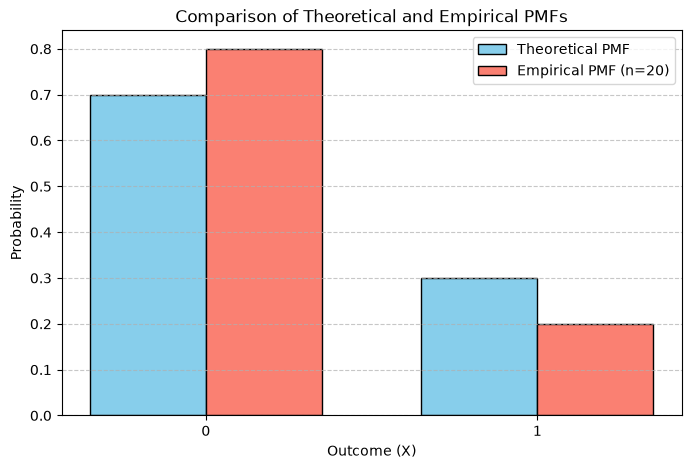

In [12]:
import matplotlib.pyplot as plt

outcomes = [0, 1]
theo_pmfs = [theo_p0, theo_p1]
emp_pmfs = [emp_p0, emp_p1]

x = np.arange(len(outcomes))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, theo_pmfs, width, label='Theoretical PMF', color='skyblue', edgecolor='black')
plt.bar(x + width/2, emp_pmfs, width, label='Empirical PMF (n=20)', color='salmon', edgecolor='black')

plt.xlabel('Outcome (X)')
plt.ylabel('Probability')
plt.title('Comparison of Theoretical and Empirical PMFs')
plt.xticks(x, outcomes)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()